In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [5]:

df = pd.read_csv(r"C:\Users\Atefah\Desktop\IRONHACK\Lab_EDA Univariate Analysis\lab-eda-univariate\amz_uk_price_prediction_dataset.csv")

df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [7]:
list(set(df.dtypes.tolist()))

[dtype('float64'), dtype('bool'), dtype('O'), dtype('int64')]

In [8]:
potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 20]
potential_categorical_from_numerical

""
0
1
2
3
4
...
2443646
2443647
2443648
2443649


In [9]:
df.select_dtypes("object").columns

Index(['asin', 'title', 'category'], dtype='object')

In [10]:
df.select_dtypes("object").nunique().sort_values(ascending=False)

asin        2222742
title       2077591
category        296
dtype: int64

In [11]:
df.columns[df.isnull().mean() > 0.8]

Index([], dtype='object')

In [12]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


see the statiscs of price 


In [13]:

df.price.describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [14]:
### Part 1: Understanding Product Categories

##**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. ##**Frequency Tables**:
    ##- Generate a frequency table for the product `category`.
    ##- Which are the top 5 most listed product categories?

2. ##**Visualizations**:
    ##- Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    ##- For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

2.0

In [ ]:

category_frequency = df['category'].value_counts()

print(category_frequency)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64


In [18]:
# Identify the top 5 most listed product categories
top_5_categories = category_frequency.head(5)
print("\nTop 5 Most Listed Product Categories:")
print(top_5_categories)


Top 5 Most Listed Product Categories:
category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


In [ ]:
##**Visualizations**:
    ##- Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    ##- For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

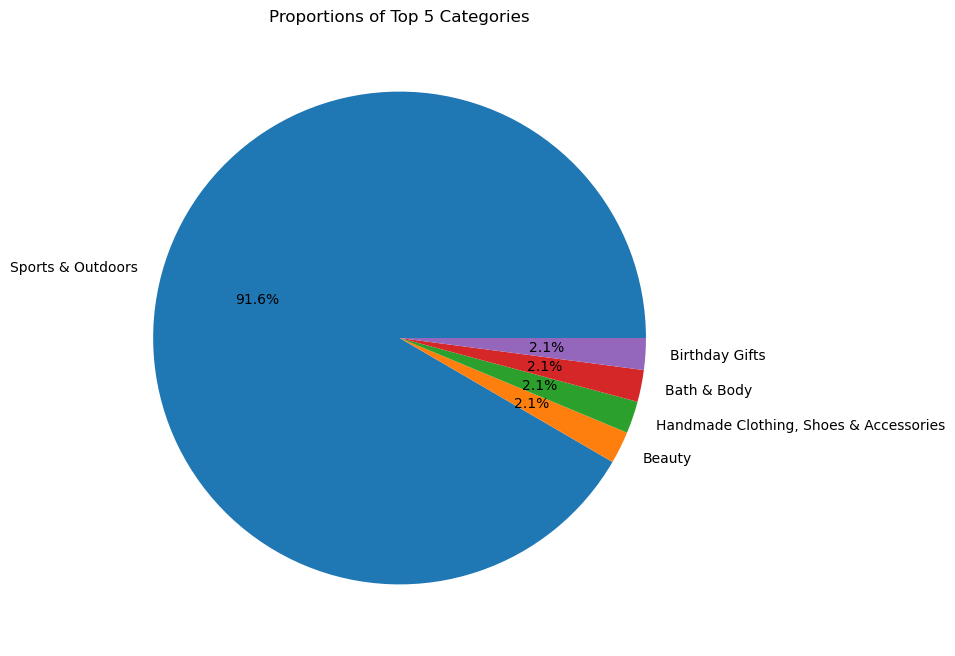

In [22]:
# Visualize the proportions of the top 5 categories using a pie chart
top_5_categories.plot(kind='pie', figsize=(8, 8), autopct='%1.1f%%', title='Proportions of Top 5 Categories')
plt.ylabel('')  # Remove the y-axis label for better visualization
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [23]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]  # Mode can return multiple values, so we take the first one

print(f"Mean Price: {mean_price}")
print(f"Median Price: {median_price}")
print(f"Mode Price: {mode_price}")

Mean Price: 89.24380943923663
Median Price: 19.09
Mode Price: 9.99


In [24]:
price_difference = mean_price - mode_price
print(f"The difference between the average price and the most common price is: {price_difference}")

The difference between the average price and the most common price is: 79.25380943923663


In [25]:
# Variance and standard deviation
price_variance = df['price'].var()
price_std_dev = df['price'].std()

# Range
price_range = df['price'].max() - df['price'].min()

# Interquartile range (IQR)
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
price_iqr = q3 - q1

print(f"Variance: {price_variance}")
print(f"Standard Deviation: {price_std_dev}")
print(f"Range: {price_range}")
print(f"Interquartile Range (IQR): {price_iqr}")

Variance: 119445.48532256528
Standard Deviation: 345.60886175352226
Range: 100000.0
Interquartile Range (IQR): 36.0


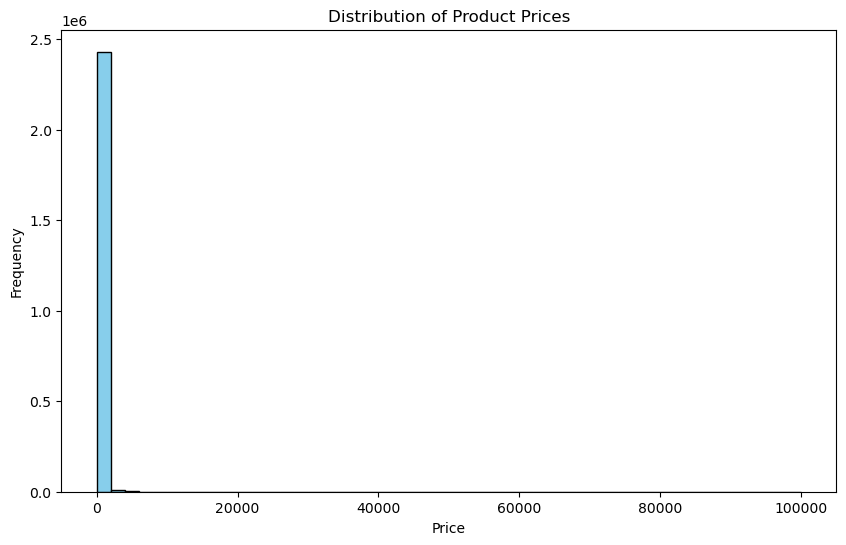

In [26]:
plt.figure(figsize=(10, 6))
plt.hist(df['price'], bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Product Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

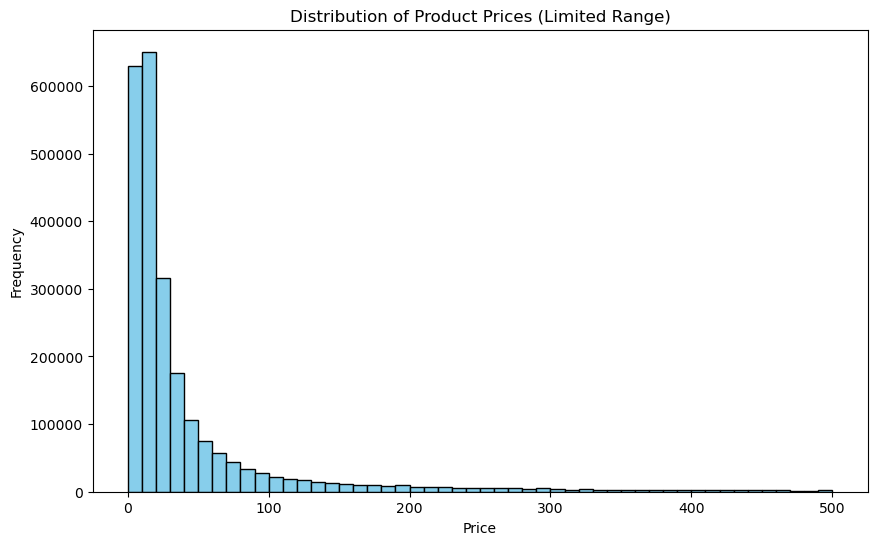

In [27]:
# If the histogram is hard to read due to outliers, limit the x-axis
plt.figure(figsize=(10, 6))
plt.hist(df['price'], bins=50, range=(0, 500), color='skyblue', edgecolor='black')
plt.title('Distribution of Product Prices (Limited Range)')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

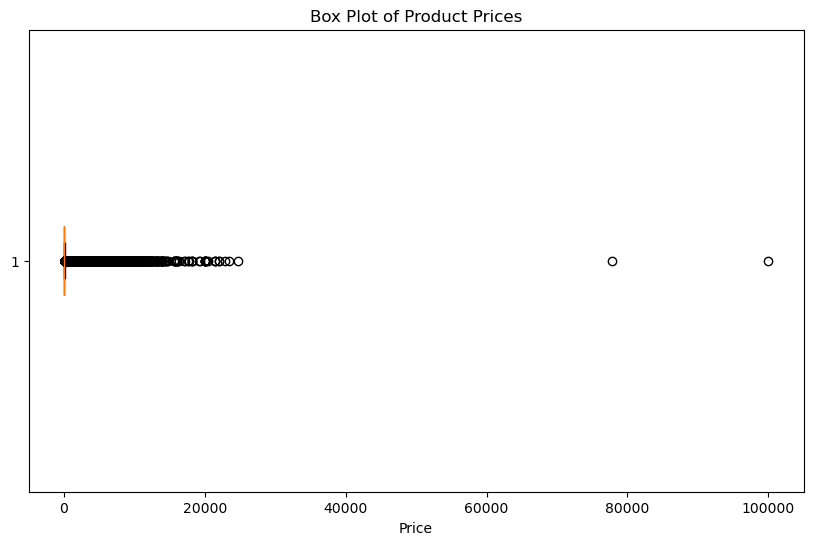

In [28]:
plt.figure(figsize=(10, 6))
plt.boxplot(df['price'], vert=False, patch_artist=True, boxprops=dict(facecolor='skyblue'))
plt.title('Box Plot of Product Prices')
plt.xlabel('Price')
plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [29]:
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]  # Mode can return multiple values, so we take the first one

print(f"Mean Rating: {mean_rating}")
print(f"Median Rating: {median_rating}")
print(f"Mode Rating: {mode_rating}")

Mean Rating: 2.152836472966065
Median Rating: 0.0
Mode Rating: 0.0


In [30]:
# Variance and standard deviation for ratings
rating_variance = df['stars'].var()
rating_std_dev = df['stars'].std()

# Interquartile range (IQR) for ratings
rating_q1 = df['stars'].quantile(0.25)
rating_q3 = df['stars'].quantile(0.75)
rating_iqr = rating_q3 - rating_q1

print(f"Variance of Ratings: {rating_variance}")
print(f"Standard Deviation of Ratings: {rating_std_dev}")
print(f"Interquartile Range (IQR) of Ratings: {rating_iqr}")

Variance of Ratings: 4.81743402976196
Standard Deviation of Ratings: 2.1948653785054697
Interquartile Range (IQR) of Ratings: 4.4


In [31]:
from scipy.stats import skew, kurtosis

# Calculate skewness and kurtosis for the 'stars' column
rating_skewness = skew(df['stars'].dropna())
rating_kurtosis = kurtosis(df['stars'].dropna())

print(f"Skewness of Ratings: {rating_skewness}")
print(f"Kurtosis of Ratings: {rating_kurtosis}")

Skewness of Ratings: 0.08120730776283354
Kurtosis of Ratings: -1.926004642549839


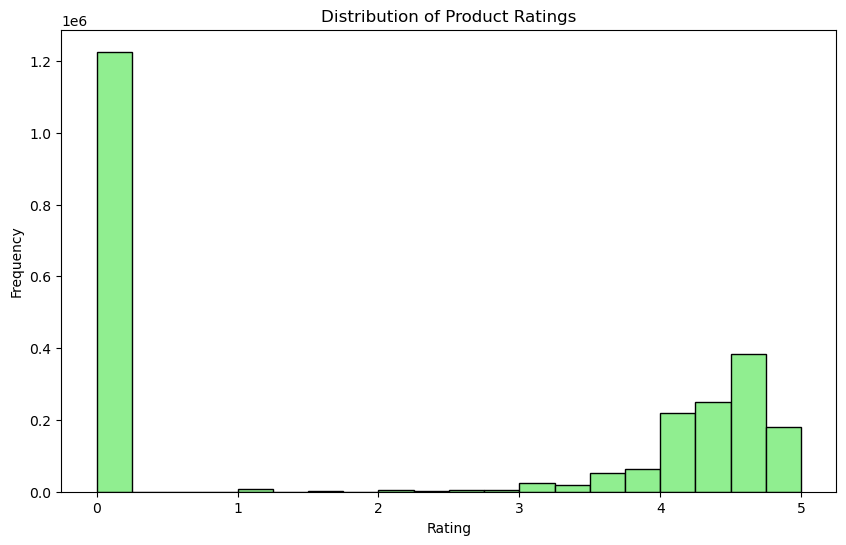

In [32]:
plt.figure(figsize=(10, 6))
plt.hist(df['stars'], bins=20, color='lightgreen', edgecolor='black')
plt.title('Distribution of Product Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# Business-Centric Report: Amazon UK Product Analysis

## Part 1: Understanding Product Categories

### Key Insights:
1. **Top 5 Most Listed Categories**:
    - The most listed product category is **Sports & Outdoors** with 836,265 listings, significantly dominating the marketplace.
    - Other notable categories include **Beauty**, **Handmade Clothing, Shoes & Accessories**, **Bath & Body**, and **Birthday Gifts**, each with listings ranging from ~19,000 to ~19,300.

2. **Category Distribution**:
    - The distribution of product categories is highly skewed, with **Sports & Outdoors** accounting for a substantial proportion of listings.
    - This dominance suggests a strong market focus on outdoor and sports-related products.

### Business Implications:
- **Opportunities**: Businesses in the **Sports & Outdoors** category can leverage the high demand and visibility in this segment.
- **Diversification**: Sellers in less represented categories may face less competition, offering opportunities for niche markets.

---

## Part 2: Product Pricing

### Key Insights:
1. **Measures of Centrality**:
    - **Mean Price**: £89.24
    - **Median Price**: £19.09
    - **Mode Price**: £9.99
    - The average price is significantly higher than the most common price, indicating the presence of high-priced products skewing the mean.

2. **Measures of Dispersion**:
    - **Price Range**: £100,000 (from £0.01 to £100,000)
    - **Interquartile Range (IQR)**: £36.00
    - **Standard Deviation**: £345.61
    - The wide range and high standard deviation highlight a significant variation in product pricing, with potential outliers.

3. **Visualizations**:
    - The histogram shows a concentration of products in the lower price range, with a long tail of high-priced items.
    - The box plot confirms the presence of outliers, likely luxury or specialized products.

### Business Implications:
- **Pricing Strategy**: Sellers should consider pricing their products near the mode (£9.99) or median (£19.09) to align with the most common price points.
- **Premium Products**: High-priced items may cater to niche markets but require targeted marketing to justify their value.

---

## Part 3: Product Ratings

### Key Insights:
1. **Measures of Centrality**:
    - **Mean Rating**: 2.15
    - **Median Rating**: 0.0
    - **Mode Rating**: 0.0
    - The low average and median ratings suggest a significant number of unrated or poorly rated products.

2. **Measures of Dispersion**:
    - **Rating Variance**: 4.82
    - **Standard Deviation**: 2.19
    - **Interquartile Range (IQR)**: 4.4
    - Ratings show a wide spread, indicating variability in customer satisfaction.

3. **Shape of Distribution**:
    - **Skewness**: 0.08 (slightly right-skewed)
    - **Kurtosis**: -1.93 (platykurtic, flatter distribution)
    - The distribution suggests a slight tendency towards higher ratings but with a significant number of low or unrated products.

### Business Implications:
- **Customer Feedback**: Encourage customers to leave reviews and ratings to improve product visibility and trust.
- **Quality Improvement**: Focus on improving product quality and addressing customer concerns to enhance ratings.

---
    

SyntaxError: invalid character '£' (U+00A3) (3008782160.py, line 24)